# Exploratory component: Which new users return within 30 days?

**Question.** Can we predict from a new user's first charging session whether the user returns within 30 days? If so, discounts can be targeted at the new users who would otherwise not return (*leavers*) instead of being given to everyone.


### Setup

Packages.

In [45]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import average_precision_score, brier_score_loss, confusion_matrix, log_loss, roc_auc_score, roc_curve

warnings.filterwarnings("ignore", category=FutureWarning)

## 1. Loading and cleaning



In [46]:
DATA_PATH = "/Users/gustavlindhardt/Desktop/Intro Business analytics/Projekt/EVChargingStationUsage.csv"

# Only the columns used in the analysis. User ID is read as text so the placeholder "0" can be recognised.
cols = ["Station Name", "Start Date", "Start Time Zone", "Total Duration (hh:mm:ss)",
        "Charging Time (hh:mm:ss)", "Energy (kWh)", "Port Type", "Fee", "Driver Postal Code", "User ID"]
raw = pd.read_csv(DATA_PATH, usecols=cols, dtype={"User ID": str})

d = raw.drop_duplicates().copy()
d["Start Date"] = pd.to_datetime(d["Start Date"], format="%m/%d/%Y %H:%M")      # month/day/year
d["Total Duration (hh:mm:ss)"] = pd.to_timedelta(d["Total Duration (hh:mm:ss)"])
d["Charging Time (hh:mm:ss)"] = pd.to_timedelta(d["Charging Time (hh:mm:ss)"])

# Columns used throughout the notebook (times in hours)
d["charge_h"] = d["Charging Time (hh:mm:ss)"].dt.total_seconds() / 3600
d["dur_h"] = d["Total Duration (hh:mm:ss)"].dt.total_seconds() / 3600
d["idle_h"] = (d["Total Duration (hh:mm:ss)"] - d["Charging Time (hh:mm:ss)"]).dt.total_seconds() / 3600   # idle time
d["day"] = d["Start Date"].dt.normalize()                                                                  # calendar day
d["site"] = d["Station Name"].str.replace("PALO ALTO CA / ", "").str.rstrip("0123456789 #")   # "PALO ALTO CA / BRYANT #1" -> "BRYANT"

# Sessions without a user ID (or with the placeholder "0") cannot be followed over time
d["missing_id"] = d["User ID"].isna() | (d["User ID"] == "0")
s = d[~d["missing_id"]].sort_values("Start Date", kind="stable").copy()

### Table 1.1: Cleaning of sessions

**What we do:** Duplicate rows are removed so that each session counts only once. Sessions without a user ID or with the ID "0" are left out, because returns can only be measured when we can recognise the same person over time.

**What the result shows:** There are only 4 duplicates. 7,677 sessions have no user ID and 453 have the ID "0". This leaves 251,281 sessions with a usable user ID.

In [47]:
# Table 1.1: Cleaning of sessions
table_1_1 = pd.DataFrame({
    "Step": ["Sessions in the dataset", "Removed: duplicates", "Removed: no user ID",
             'Removed: user ID "0"', "Sessions with a user ID"],
    "Count": [len(raw), len(raw) - len(d), d["User ID"].isna().sum(), (d["User ID"] == "0").sum(), len(s)],
}).set_index("Step")
table_1_1

,Count
Step,
Sessions in the dataset,259415
Removed: duplicates,4
Removed: no user ID,7677
"Removed: user ID ""0""",453
Sessions with a user ID,251281


### Table 1.2: Are sessions without a user ID different?

**What we do:** Leaving out the sessions without a user ID is only harmless if they do not differ systematically from the rest. We therefore compare the two groups on typical energy, charging time, idle time and share at weekends, and look at how large a share they make up each year.

**What the result shows:** Sessions without an ID are similar to the rest: median energy is 7.1 vs. 6.9 kWh, charging time 1.78 vs. 1.82 hours, idle time is the same, and the weekend share is 25.38% vs. 23.81%. They make up 4–6% of sessions in 2011–2014 and 2–4% from 2015 onwards. The ID "0" only occurs until September 2015.

**What we use it for:** The assumption that the excluded sessions do not differ systematically is supported, and since there are few of them, we assume that they wouldn't have changed the results much.

**Limitation:** We cannot see whether an excluded user later creates an account. If so, that person counts as new when the account is first used.

In [48]:
# Table 1.2: Sessions with and without a user ID (whole period)
d["weekend"] = d["Start Date"].dt.day_of_week >= 5

table_1_2 = d.groupby("missing_id").agg(
    sessions=("Fee", "size"),
    energy_median_kwh=("Energy (kWh)", "median"),
    charging_median_h=("charge_h", "median"),
    idle_median_h=("idle_h", "median"),
    weekend_share_pct=("weekend", "mean"),
)
table_1_2["weekend_share_pct"] *= 100
table_1_2.index = ["With user ID", "Without user ID"]
table_1_2.round(2)

,sessions,energy_median_kwh,charging_median_h,idle_median_h,weekend_share_pct
With user ID,251281,6.86,1.82,0.01,23.81
Without user ID,8130,7.06,1.78,0.01,25.38


In [49]:
# Share of sessions without a usable user ID per year (supplement to Table 1.2)
print('Last occurrence of user ID "0":', d.loc[d["User ID"] == "0", "Start Date"].max().date())
(d.groupby(d["Start Date"].dt.year)["missing_id"].mean() * 100).round(1).rename("share_without_id_pct").to_frame().T

Last occurrence of user ID "0": 2015-09-02


Start Date,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
share_without_id_pct,5.5,5.8,4.9,4.1,3.3,3.0,3.0,2.2,2.9,3.6


## 2. What do the data look like?

Before defining the cohort, we look at what the data contain, how usage develops over time and how often users charge.

### Table 2.1: Overview

**What the result shows:** The cleaned data cover 29 July 2011 – 31 December 2020 with 251,281 sessions from 21,440 users on 47 chargers at 9 locations. A typical session delivers 6.9 kWh over 1.8 hours of charging, and the car stays at the charger for 2.1 hours in total. Almost all sessions (98.2%) are on Level 2 chargers.

In [50]:
# Table 2.1: Overview of sessions with a user ID
table_2_1 = pd.Series({
    "First session": s["Start Date"].min().date(),
    "Last session": s["Start Date"].max().date(),
    "Sessions": len(s),
    "Users": s["User ID"].nunique(),
    "Chargers (Station Name)": s["Station Name"].nunique(),
    "Locations": s["site"].nunique(),
    "Energy per session, median (kWh)": round(s["Energy (kWh)"].median(), 1),
    "Charging time per session, median (h)": round(s["charge_h"].median(), 2),
    "Total duration per session, median (h)": round(s["dur_h"].median(), 2),
    "Share on Level 2 chargers (%)": round((s["Port Type"] == "Level 2").mean() * 100, 1),
}).to_frame("Value")
table_2_1

,Value
First session,2011-07-29
Last session,2020-12-31
Sessions,251281
Users,21440
Chargers (Station Name),47
Locations,9
"Energy per session, median (kWh)",6.9
"Charging time per session, median (h)",1.82
"Total duration per session, median (h)",2.09
Share on Level 2 chargers (%),98.2


### Figure 2.1: Usage over time

**What we do:** We count charging sessions per month for the whole period (all sessions, including those without a user ID).

**What the figure shows:** Usage grows steadily from 2011 to about 5,000 sessions per month in summer 2017. After that there are two clear breaks. In August 2017 usage falls by about a third and then stays fairly stable at 3,000–4,500 per month. In March 2020 it collapses and has only partly recovered by the end of the year.

**What we use it for:** The two breaks appear to change the conditions for users, so we examine them more closely in section 3 (Tables 3.1–3.3 and Figure 3.2) before restricting the period.

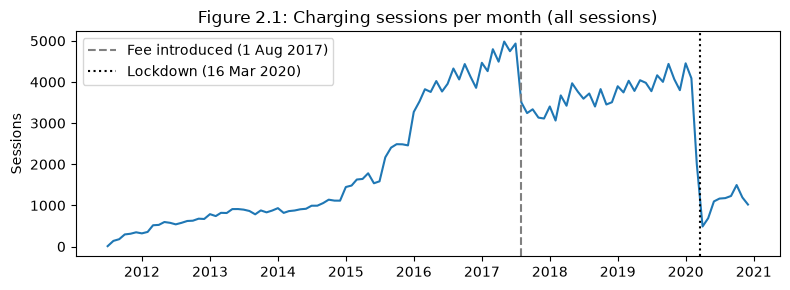

In [51]:
# Figure 2.1: Charging sessions per month
FEE_START = pd.Timestamp("2017-08-01")    # fee introduced (examined in section 3.2)
LOCKDOWN = pd.Timestamp("2020-03-16")     # lockdown (examined in section 3.3)

per_month = d.groupby(d["Start Date"].dt.to_period("M")).size()

plt.figure(figsize=(8, 3))
plt.plot(per_month.index.to_timestamp(), per_month.values)
plt.axvline(FEE_START, color="grey", linestyle="--", label="Fee introduced (1 Aug 2017)")
plt.axvline(LOCKDOWN, color="black", linestyle=":", label="Lockdown (16 Mar 2020)")
plt.title("Figure 2.1: Charging sessions per month (all sessions)")
plt.ylabel("Sessions")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Table 2.2: How often do users charge?

**What we do:** We count sessions per user over the whole period and group the users.

**What the result shows:** 43.7% of users charge only once, and 72% charge fewer than five times. Conversely, the 4.8% of users who charge at least 50 times account for 61.8% of all sessions.

**What we use it for:** This motivates the question. Many new users never return, while regular users account for most of the usage. If we can tell early which new users will not return, a discount can be targeted at them. The focus is therefore on new users and their first visit.

In [52]:
# Table 2.2: Users by number of sessions
sessions_per_user = s.groupby("User ID").size()
group = pd.cut(sessions_per_user, [0, 1, 4, 9, 49, np.inf], labels=["1", "2–4", "5–9", "10–49", "50+"])

table_2_2 = pd.DataFrame({
    "users": sessions_per_user.groupby(group, observed=False).size(),
    "sessions": sessions_per_user.groupby(group, observed=False).sum(),
})
table_2_2["share_users_pct"] = (table_2_2["users"] / table_2_2["users"].sum() * 100).round(1)
table_2_2["share_sessions_pct"] = (table_2_2["sessions"] / table_2_2["sessions"].sum() * 100).round(1)
table_2_2.index.name = "sessions per user"
table_2_2

,users,sessions,share_users_pct,share_sessions_pct
sessions per user,,,,
1,9370,9370,43.7,3.7
2–4,6090,16106,28.4,6.4
5–9,2374,15511,11.1,6.2
10–49,2582,54977,12.0,21.9
50+,1024,155317,4.8,61.8


## 3. From question to cohort

To measure whether new users return, three things must be fixed: (1) who counts as a new user, (2) which period can be used, and (3) how long we wait before a user counts as a leaver. We make the three choices one at a time and then define the cohort.

### 3.1 Who is a new user? (Figure 3.1)

**What we do:** After sorting by time, a user's first session is the earliest one in the entire history of the dataset (from 2011). This ensures that a user who has been charging since 2015 is not wrongly counted as "new" in 2017. We count in calendar days from the day of the first visit, because the question is whether the user comes back on a later day. A new session on the same day (e.g. after an interrupted charge or to move the car) is not loyalty, so only sessions on a later day count.

**What the figure shows:** The number of new users grows over time, from about 170 per month in 2015 through about 190–280 in 2016 to July 2017, to about 280–430 from August 2017. There is no one-off spike when the fee is introduced, as there would be if existing users were suddenly registered as new. New users jumps from 278 in July to 344 in August 2017 and then stays at that level.

**What we use it for:** The definition "first seen in the entire dataset" appears to capture genuinely new users, and about 300–400 new users arrive each month.

**Limitation:** We have not seeked to explain the jump in August 2017 from the data. It may be real growth or a change in how users are registered when payment is introduced. However, users from the first months after the jump do not return noticeably more often than later users (Figure 4.1), which argues against them being old regular users with new IDs.

In [53]:
# First visit and days to the next visit
s["gap"] = (s["day"] - s.groupby("User ID")["day"].transform("min")).dt.days   # days after the first visit

first = s.drop_duplicates("User ID").set_index("User ID")                       # first session per user
first["days_to_2nd"] = s[s["gap"] > 0].groupby("User ID")["gap"].min()         # NaN = never returned
first["sessions_day1"] = s[s["gap"] == 0].groupby("User ID").size()             # sessions on the first day
print(len(first), "users")

21440 users


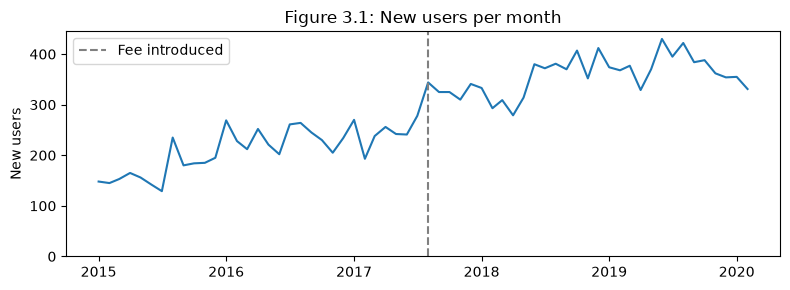

day
2017-05    242
2017-06    241
2017-07    278
2017-08    344
2017-09    325
2017-10    325
Freq: M, dtype: int64

In [54]:
# Figure 3.1: New users per month
new_users = first.groupby(first["day"].dt.to_period("M")).size().loc["2015-01":"2020-02"]

plt.figure(figsize=(8, 3))
plt.plot(new_users.index.to_timestamp(), new_users.values)
plt.axvline(FEE_START, color="grey", linestyle="--", label="Fee introduced")
plt.title("Figure 3.1: New users per month")
plt.ylabel("New users")
plt.ylim(0, None)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

new_users.loc["2017-05":"2017-10"]     # the numbers cited in the text

### 3.2 When does the period start? The fee from August 2017 (Tables 3.1–3.3)

**What we do:** Figure 2.1 shows a drop in August 2017. We examine whether it is caused by the introduction of a fee and whether the price is stable afterwards. Table 3.1 shows, per month from March to December 2017, the number of sessions, the share of free sessions and the mean fee. Table 3.2 shows, per quarter, the median price per kWh and the share of sessions priced at $0.22–0.24 per kWh. Since 10–12% of sessions fall outside this range, Table 3.3 divides all sessions in the period into price groups and compares them.

**What the result shows:** From March to July 2017 all sessions are free. In August the share of free sessions falls to 5.3%, and from September to 0.7%, and the mean fee becomes about $2 per session. At the same time the number of sessions falls by about a third, from about 4,800 per month (March–July) to about 3,200 (September–December). The drop is not seasonal: in the same months of 2016 the number rose from about 3,900 to about 4,100 (Figure 2.1). The median price is $0.23 per kWh in every quarter from 2017 Q3 to 2020 Q1, and 88–90% of sessions cost $0.22–0.24 per kWh in each quarter. Table 3.3 shows who the remaining sessions are. Sessions above $0.24 per kWh (9.2% of sessions) appear to follow the same tariff plus a time-based charge: they deliver about the same energy (6.9 vs. 7.2 kWh), but the car stays at the charger much longer (median idle time 1.2 vs. 0.01 hours), and their extra fee beyond $0.23 per kWh correlates strongly with idle time (0.80). Sessions with a zero fee (0.9%) are not free charging but mostly aborted sessions that delivered almost no energy (median 0.07 kWh; 77% below 0.5 kWh). The price structure is therefore the same throughout the period, and the share outside the range is stable.

**What we use it for:** The period starts when the fee is introduced, on 1 August 2017. Before that, charging was free, so users' value in fees is zero by definition, and their behaviour is not comparable with users under a paid regime. The price is stable afterwards, so the whole period is treated as one regime, and the sessions outside $0.22–0.24 are not treated separately. We cannot see the tariff rules in the data, so the time-based charge is an interpretation. The drop in sessions also suggests that users respond to price, which makes a discount campaign relevant.

**Limitation:** There is no control group, because the fee is introduced at all stations at once, so the drop could also be caused by other changes in August 2017.

In [55]:
# Table 3.1: Sessions and fees per month, March–December 2017 (all sessions)
m = d[(d["Start Date"] >= "2017-03-01") & (d["Start Date"] < "2018-01-01")]
table_3_1 = m.groupby(m["Start Date"].dt.to_period("M")).agg(
    sessions=("Fee", "size"),
    share_free_pct=("Fee", lambda f: (f == 0).mean() * 100),
    mean_fee=("Fee", "mean"),
)
table_3_1.round(2)

,sessions,share_free_pct,mean_fee
Start Date,,,
2017-03,4797,100.00,0.00
2017-04,4494,100.00,0.00
2017-05,4983,100.00,0.00
2017-06,4749,100.00,0.00
2017-07,4935,100.00,0.00
2017-08,3505,5.28,1.86
2017-09,3244,0.71,1.95
2017-10,3336,0.75,2.00
2017-11,3134,0.70,2.07


In [56]:
# Table 3.2: Price per kWh per quarter, August 2017 – March 2020 (sessions above 1 kWh)
p = d[(d["Start Date"] >= FEE_START) & (d["Start Date"] < LOCKDOWN) & (d["Energy (kWh)"] > 1)].copy()
p["price_per_kwh"] = p["Fee"] / p["Energy (kWh)"]

table_3_2 = p.groupby(p["Start Date"].dt.to_period("Q"))["price_per_kwh"].agg(
    median_price="median",
    share_022_024_pct=lambda x: x.between(0.22, 0.24).mean() * 100,
)
table_3_2.round(2).T

Start Date,2017Q3,2017Q4,2018Q1,2018Q2,2018Q3,2018Q4,2019Q1,2019Q2,2019Q3,2019Q4,2020Q1
median_price,0.23,0.23,0.23,0.23,0.23,0.23,0.23,0.23,0.23,0.23,0.23
share_022_024_pct,89.59,88.25,89.31,88.71,88.27,87.83,90.00,90.05,89.99,90.02,90.08


In [57]:
# Table 3.3: Price groups among sessions, August 2017 – March 2020 (all sessions)
q = d[(d["Start Date"] >= FEE_START) & (d["Start Date"] < LOCKDOWN)].copy()
q["price_per_kwh"] = q["Fee"] / q["Energy (kWh)"]
q["price_group"] = np.select(
    [q["Fee"] == 0, q["Energy (kWh)"] <= 1, q["price_per_kwh"] < 0.22, q["price_per_kwh"] <= 0.24],
    ["free (fee 0)", "1 kWh or less", "below 0.22", "0.22–0.24"], default="above 0.24")
q["extra_fee"] = q["Fee"] - 0.23 * q["Energy (kWh)"]          # fee beyond $0.23 per kWh

table_3_3 = q.groupby("price_group").agg(
    sessions=("Fee", "size"),
    energy_median_kwh=("Energy (kWh)", "median"),
    duration_median_h=("Total Duration (hh:mm:ss)", lambda x: x.dt.total_seconds().median() / 3600),
    idle_median_h=("idle_h", "median"),
    fee_median=("Fee", "median"),
    share_below_05_kwh_pct=("Energy (kWh)", lambda x: (x < 0.5).mean() * 100),
).reindex(["0.22–0.24", "above 0.24", "below 0.22", "1 kWh or less", "free (fee 0)"])
table_3_3.insert(1, "share_sessions_pct", table_3_3["sessions"] / table_3_3["sessions"].sum() * 100)

above = q[q["price_group"] == "above 0.24"]
print("Sessions above $0.24 per kWh: correlation between extra fee and idle time =",
      round(np.corrcoef(above["extra_fee"], above["idle_h"])[0, 1], 2),
      ", and total duration =", round(np.corrcoef(above["extra_fee"], above["Total Duration (hh:mm:ss)"].dt.total_seconds())[0, 1], 2))
table_3_3.round(2)

Sessions above $0.24 per kWh: correlation between extra fee and idle time = 0.8 , and total duration = 0.72


,sessions,share_sessions_pct,energy_median_kwh,duration_median_h,idle_median_h,fee_median,share_below_05_kwh_pct
price_group,,,,,,,
0.22–0.24,99531,85.03,7.18,1.90,0.01,1.65,0.00
above 0.24,10810,9.23,6.87,3.27,1.17,3.17,0.00
below 0.22,891,0.76,8.18,2.08,0.02,1.35,0.00
1 kWh or less,4796,4.10,0.60,0.18,0.01,0.14,37.95
free (fee 0),1029,0.88,0.07,0.03,0.01,0.00,77.45


### 3.3 When does the period end? The lockdown in March 2020 (Figure 3.2)

**What we do:** Figure 2.1 also shows a collapse in March 2020. We count sessions per week from January to early May 2020.

**What the result shows:** In January and February the level is stable at 972–1,082 sessions per week (mean about 1,020). Activity already falls in early March (879 in the week of 2 March and 664 in the week of 9 March) and drops sharply to 182 in the week of 16 March. From 23 March there are 97–133 sessions per week, about 87–90% below the pre-lockdown level, with no sign of recovery.

**What we use it for:** After the lockdown, not returning reflects the pandemic rather than the user's relationship with the service. All users' return windows must therefore lie before 16 March 2020, and the period for first visits ends so that this holds (section 3.5).

**Limitation:** The decline starts in the weeks before 16 March, so the last users' windows are partly affected.

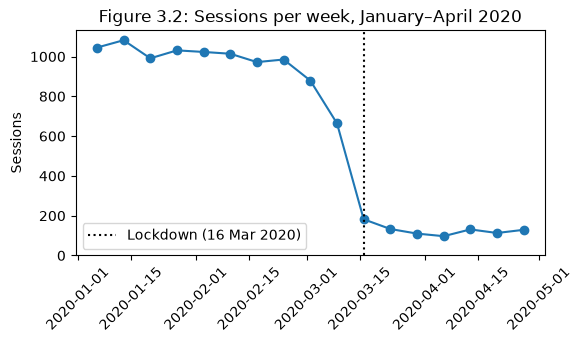

Start Date
2020-01-06/2020-01-12    1045
2020-01-13/2020-01-19    1082
2020-01-20/2020-01-26     991
2020-01-27/2020-02-02    1031
2020-02-03/2020-02-09    1023
2020-02-10/2020-02-16    1014
2020-02-17/2020-02-23     972
2020-02-24/2020-03-01     985
2020-03-02/2020-03-08     879
2020-03-09/2020-03-15     664
2020-03-16/2020-03-22     182
2020-03-23/2020-03-29     133
2020-03-30/2020-04-05     110
2020-04-06/2020-04-12      97
2020-04-13/2020-04-19     131
2020-04-20/2020-04-26     113
2020-04-27/2020-05-03     129
Freq: W-SUN, dtype: int64

In [58]:
# Figure 3.2: Sessions per week around the lockdown
week = d[(d["Start Date"] >= "2020-01-06") & (d["Start Date"] < "2020-05-04")]
per_week = week.groupby(week["Start Date"].dt.to_period("W")).size()

plt.figure(figsize=(6, 3))
plt.plot(per_week.index.start_time, per_week.values, marker="o")
plt.axvline(LOCKDOWN, color="black", linestyle=":", label="Lockdown (16 Mar 2020)")
plt.title("Figure 3.2: Sessions per week, January–April 2020")
plt.ylabel("Sessions")
plt.ylim(0, None)
plt.legend()
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()


per_week                              

### 3.4 How long do we wait? Choice of time window (Tables 3.4–3.5, Figure 3.3)

**What we do:** We need to define what it means for a new user to "return". We compare six windows (7, 14, 30, 60, 90 and 365 days) and compute for each the share of new users who have a new session on a later calendar day within the window. The population is new users with a first visit between the introduction of the fee and 365 days before the lockdown (6,779 users). That way everyone can be followed for a full year, and all windows are compared on the same users.

**What the result shows:** The share rises from 10.4% (7 days) to 20.1% (30 days) and 44.5% (365 days), but the daily increase slows quickly: from 0.37 percentage points per day between 14 and 30 days to 0.20 between 30 and 60 days. Almost half of of those who return do so early: 45% of those who return within a year are back within 30 days. 55.5% do not return within a year.

In [59]:
# Table 3.4: Share who return within different windows
# New users who can be followed for a full year before the lockdown
pop = first[(first["day"] >= FEE_START) & (first["day"] < LOCKDOWN - pd.Timedelta(days=365))].copy()

windows = [7, 14, 30, 60, 90, 365]
table_3_4 = pd.DataFrame({"window_days": windows,
                          "share_returned_pct": [(pop["days_to_2nd"] <= w).mean() * 100 for w in windows]})
# increase in percentage points per day since the previous window
table_3_4["increase_pp_per_day"] = table_3_4["share_returned_pct"].diff().fillna(table_3_4["share_returned_pct"]) \
                                    / table_3_4["window_days"].diff().fillna(table_3_4["window_days"])
print(len(pop), "new users with one year of follow-up")
table_3_4.round(2)

6779 new users with one year of follow-up


,window_days,share_returned_pct,increase_pp_per_day
0,7,10.41,1.49
1,14,14.21,0.54
2,30,20.11,0.37
3,60,26.21,0.20
4,90,30.11,0.13
5,365,44.52,0.05


**What is a returning user worth?** For the same 6,779 users we sum the fees and count the sessions in the year after the first visit (days 1–365; the first visit and sessions on the same day are not included) and group users by when they first returned (Table 3.5). Those who return within 30 days (20.1%) pay on average $42.62 in the following year, compared with $14.25 for 31–60 days and $4.16 for 91–365 days, and they account for 82.7% of all fees in the following year. The mean is far above the median ($42.62 vs. $8.14), so value is concentrated among relatively few heavy users. The ranking holds with the median too ($8.14 > $4.11 > $2.86 > $2.23 > $0).

In [60]:
# Table 3.5: Fees and sessions in the year after the first visit, by when the user returned
next_year = s[(s["gap"] > 0) & (s["gap"] <= 365)].groupby("User ID")
pop["fees_next_year"] = next_year["Fee"].sum().reindex(pop.index, fill_value=0)
pop["sessions_next_year"] = next_year.size().reindex(pop.index, fill_value=0)
pop["returned_after"] = pd.cut(pop["days_to_2nd"].fillna(np.inf), [0, 30, 60, 90, 365, np.inf],
                               labels=["1–30 days", "31–60 days", "61–90 days", "91–365 days", "Not within a year"])

table_3_5 = pop.groupby("returned_after", observed=True).agg(
    users=("fees_next_year", "size"),
    mean_fees=("fees_next_year", "mean"),
    median_fees=("fees_next_year", "median"),
    mean_sessions=("sessions_next_year", "mean"),
    total_fees=("fees_next_year", "sum"),
)
table_3_5["share_users_pct"] = table_3_5["users"] / table_3_5["users"].sum() * 100
table_3_5["share_fees_pct"] = table_3_5["total_fees"] / table_3_5["total_fees"].sum() * 100
table_3_5.drop(columns="total_fees").round(2)

,users,mean_fees,median_fees,mean_sessions,share_users_pct,share_fees_pct
returned_after,,,,,,
1–30 days,1363,42.62,8.14,17.26,20.11,82.72
31–60 days,414,14.25,4.11,5.91,6.11,8.40
61–90 days,264,8.21,2.86,3.81,3.89,3.09
91–365 days,977,4.16,2.23,2.24,14.41,5.79
Not within a year,3761,0.00,0.00,0.00,55.48,0.00


**What Figure 3.3 shows:** Panel (a) shows Table 3.4 as a curve: for each day t from 1 to 365, the share of the 6,779 users who have returned by day t. The curve rises steeply in the first weeks and then flattens gradually without a break, so the choice of window is a trade-off rather than a statistical optimum. Panel (b) shows Table 3.5: fees fall sharply the later the user returns.

**What we use it for:** We choose 30 days (`WINDOW = 30` in section 3.5) because
1. the positive class is large enough for the model to learn something (about 20% vs. about 10% at 7 days),
2. the window is short enough for a campaign to reach the user while it is still open whether they will return, and the label is known sooner, so the buffer in the split is shorter than with 60 or 90 days,
4. value drops most between the 1–30 day group and the 31–60 day group (to a third).

**Limitation:** A user who has not returned after 30 days is not necessarily lost: about 31% of them return within a year. The model identifies users with a low probability of a quick return, not definitive leavers. The value differences are descriptive, not causal: quick returners may be heavy users to begin with, and late returners mechanically have less time to pay fees within the 365 days.

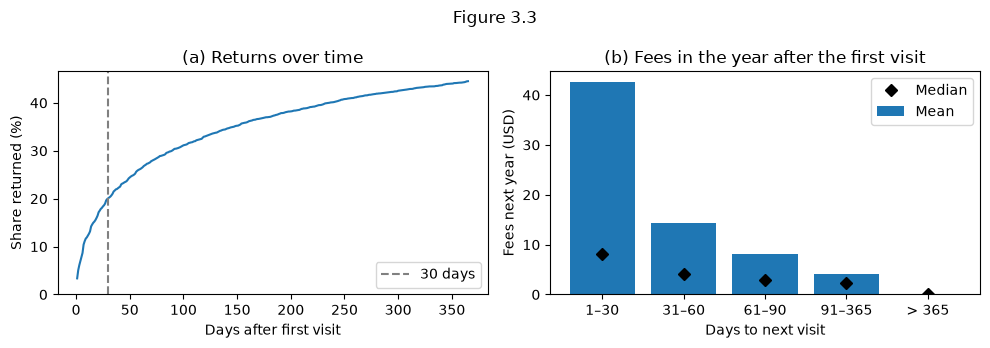

In [61]:
# Figure 3.3: (a) returns over time and (b) fees in the year after the first visit
days = np.arange(1, 366)
curve = [(pop["days_to_2nd"] <= t).mean() * 100 for t in days]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(days, curve)
ax1.axvline(30, color="grey", linestyle="--", label="30 days")
ax1.set_xlabel("Days after first visit")
ax1.set_ylabel("Share returned (%)")
ax1.set_title("(a) Returns over time")
ax1.set_ylim(0, None)
ax1.legend()

x = np.arange(len(table_3_5))
ax2.bar(x, table_3_5["mean_fees"], label="Mean")
ax2.plot(x, table_3_5["median_fees"], "D", color="black", label="Median")
ax2.set_xticks(x, ["1–30", "31–60", "61–90", "91–365", "> 365"])
ax2.set_xlabel("Days to next visit")
ax2.set_ylabel("Fees next year (USD)")
ax2.set_title("(b) Fees in the year after the first visit")
ax2.legend()

fig.suptitle("Figure 3.3")
plt.tight_layout()
plt.show()

### 3.5 Cohort and target variable (Table 3.6)

With the three choices in place, we define the cohort: new users with a first visit from **1 August 2017** (the fee, section 3.2) to **14 February 2020**, i.e. 30 days before the lockdown (sections 3.3–3.4). This way all users have a full 30-day window, no one has a better chance of returning merely because they arrived early in the period, and no one is wrongly counted as a leaver because we have not followed them long enough.

**Target variable:** `returned` = 1 if the next visit is at most 30 days after the first, and `leaver` = 1 − `returned`.

**What the result shows:** Of the 21,440 users, 9,578 had their first visit before the fee and are therefore not new in the period, and 950 arrived so late that they cannot be followed for 30 days before the lockdown. This leaves 10,912 new users, of whom 2,193 (20.1%) returned within 30 days. The classes are thus imbalanced, with about 80% leavers.

**Limitation:** Returns are only observed at these stations, so a leaver may still charge elsewhere, and "new" means new in the dataset. The cohort therefore says something about who comes back to Palo Alto's stations, not about who stops charging an electric car.

In [62]:
# Cohort and target variable
WINDOW = 30                                                # chosen in section 3.4
COHORT_END = LOCKDOWN - pd.Timedelta(days=WINDOW)          # first visit no later than 14 February 2020

cohort = first[(first["day"] >= FEE_START) & (first["day"] < COHORT_END)].copy()
cohort["returned"] = (cohort["days_to_2nd"] <= WINDOW).astype(int)   # NaN <= 30 is False: never returned -> 0
cohort["leaver"] = 1 - cohort["returned"]
print(len(cohort), "new users,", round(cohort["returned"].mean() * 100, 1), "% returned within 30 days")

10912 new users, 20.1 % returned within 30 days


In [63]:
# Table 3.6: From users to cohort
table_3_6 = pd.DataFrame({
    "Step": ["Users with a user ID", "Removed: first visit before 1 Aug 2017",
             "Removed: first visit on 15 Feb 2020 or later", "Cohort: new users",
             "Of which returned within 30 days"],
    "Count": [len(first), (first["day"] < FEE_START).sum(), (first["day"] >= COHORT_END).sum(),
              len(cohort), cohort["returned"].sum()],
}).set_index("Step")
table_3_6

,Count
Step,
Users with a user ID,21440
Removed: first visit before 1 Aug 2017,9578
Removed: first visit on 15 Feb 2020 or later,950
Cohort: new users,10912
Of which returned within 30 days,2193


### 3.6 Data quality of the first visits (Table 3.7)

**What we do:** Since the features come from the first visit, we check the cohort's first visits for interrupted or unusual sessions and for values that could cause problems in the model.

**What the result shows:** There are few problems, and none requires removing users. The most important is that 386 users (3.5%) have more than one session on the first day. For 153 of them the first session was below 0.5 kWh, typically an interrupted charge followed by a new attempt. We use only the first session for the features, so the model can be applied right after the first visit. Defining the first visit as the whole first day instead hardly changes the AUC (Table 6.7), so the choice does not affect the results. Port type hardly varies and is therefore not used as a feature. The 179 users with a free first session are almost all aborted sessions (see section 3.2). The cell below Table 3.7 checks whether users return differently depending on the price group of their first session (as in Table 3.3): they do not (18.1–24.0%, χ² test p = 0.34), so price groups are not treated separately.

In [64]:
# Table 3.7: Data quality of the cohort's first visits
table_3_7 = pd.DataFrame({"Check": [
    "First session below 0.5 kWh",
    "More than one session on the first day",
    "  of which first session below 0.5 kWh",
    "Negative idle time (charging > total duration)",
    "Total duration above 24 hours",
    "Free first session (fee 0)",
    "Port type Level 1",
    "Missing postal code",
    "Start time recorded in UTC",
], "Users": [
    (cohort["Energy (kWh)"] < 0.5).sum(),
    (cohort["sessions_day1"] > 1).sum(),
    ((cohort["sessions_day1"] > 1) & (cohort["Energy (kWh)"] < 0.5)).sum(),
    (cohort["idle_h"] < 0).sum(),
    (cohort["dur_h"] > 24).sum(),
    (cohort["Fee"] == 0).sum(),
    (cohort["Port Type"] == "Level 1").sum(),
    cohort["Driver Postal Code"].isna().sum(),
    (cohort["Start Time Zone"] == "UTC").sum(),
]}).set_index("Check")
table_3_7["share_pct"] = (table_3_7["Users"] / len(cohort) * 100).round(2)
table_3_7

,Users,share_pct
Check,,
First session below 0.5 kWh,374,3.43
More than one session on the first day,386,3.54
of which first session below 0.5 kWh,153,1.40
Negative idle time (charging > total duration),0,0.00
Total duration above 24 hours,2,0.02
Free first session (fee 0),179,1.64
Port type Level 1,4,0.04
Missing postal code,14,0.13
Start time recorded in UTC,1,0.01


In [65]:
# Return rate by price group of the first session (supplement to Table 3.7)
first_price = cohort["Fee"] / cohort["Energy (kWh)"]
cohort_price_group = np.select(
    [cohort["Fee"] == 0, cohort["Energy (kWh)"] <= 1, first_price < 0.22, first_price <= 0.24],
    ["free (fee 0)", "1 kWh or less", "below 0.22", "0.22–0.24"], default="above 0.24")

print("χ² test across price groups, p =",
      round(stats.chi2_contingency(pd.crosstab(cohort_price_group, cohort["returned"]))[1], 3))
returns_by_price = cohort.groupby(cohort_price_group)["returned"].agg(users="size", share_returned_pct="mean")
returns_by_price["share_returned_pct"] *= 100
returns_by_price.reindex(["0.22–0.24", "above 0.24", "below 0.22", "1 kWh or less", "free (fee 0)"]).round(1)

χ² test across price groups, p = 0.343


,users,share_returned_pct
0.22–0.24,9337,20.3
above 0.24,806,18.5
below 0.22,83,21.7
1 kWh or less,507,18.1
free (fee 0),179,24.0


## 4. Time-based split

**What we do:** We split the cohort by time rather than at random, because in practice the model has to predict for future users. A random split lets the model see the future (e.g. growth in the EV market and a changing user mix) and gives overly optimistic results. Training covers first visits before 2 May 2019, test from 1 June 2019. The buffer consists of the new users whose first visit falls within the 30 days before the cut-off date of 1 June 2019. Their label is determined by behaviour after the cut-off date, i.e. in the test period, so they are left out. Each user has only one row and therefore appears in only one of the sets.

**What the result shows (Table 4.1):** Training has 7,306 users (about 67%), test 3,247 and the buffer 359. The share who return is 20.1% in both training and test. All 8 locations appear in both sets, so the model does not meet unknown stations in the test set.

In [66]:
# Time-based split with a 30-day buffer
CUTOFF = pd.Timestamp("2019-06-01")                    # the test period starts here
TRAIN_END = CUTOFF - pd.Timedelta(days=WINDOW)         # training: first visit before 2 May 2019

cohort = cohort.sort_values("Start Date", kind="stable")   # chronological (used by the cross-validation)
cohort["set"] = np.select([cohort["day"] < TRAIN_END, cohort["day"] >= CUTOFF], ["train", "test"], default="buffer")

print("Locations in test that are not in training:",
      set(cohort.loc[cohort["set"] == "test", "site"]) - set(cohort.loc[cohort["set"] == "train", "site"]))

Locations in test that are not in training: set()


In [67]:
# Table 4.1: Chronological split by first visit
table_4_1 = cohort.groupby("set").agg(
    first_visit_from=("day", "min"),
    first_visit_to=("day", "max"),
    users=("returned", "size"),
    returned=("returned", "sum"),
    share_returned_pct=("returned", "mean"),
).reindex(["train", "buffer", "test"])
table_4_1["share_returned_pct"] = (table_4_1["share_returned_pct"] * 100).round(1)
table_4_1

,first_visit_from,first_visit_to,users,returned,share_returned_pct
set,,,,,
train,2017-08-01,2019-05-01,7306,1466,20.1
buffer,2019-05-02,2019-05-31,359,74,20.6
test,2019-06-01,2020-02-14,3247,653,20.1


### Is the return rate stable over time? (Figure 4.1, Table 4.2)

**What we do:** A time-based split only gives a fair picture if the test period resembles the training period. For each month we compute the share of new users who returned within 30 days, with a 95% interval. Table 4.2 tests (1) whether there is a trend over time (logistic regression of `returned` on time), (2) whether the months differ (χ² test), (3) whether there is a seasonal pattern, and (4) whether the share is the same in training and test.

**What the result shows:** The rate varies between about 16% and 25% from month to month, but there is no trend over time (odds ratio 0.97 per year, p = 0.39). The months differ only weakly (p = 0.049), and the difference is mainly due to a seasonal pattern: users who start in November–December return less often (17.3% vs. 20.8%, p < 0.001), possibly because their 30-day window falls in the holiday period. The share is 20.1% in both training and test (p = 0.98).

**What we use it for:** There is no trend that makes the test period different from the training period, so performance on the test data is a realistic estimate of how the model will do on future users. The seasonal pattern is present in both the training and the test period, and a November–December indicator hardly changes the cross-validated AUC (+0.002, Table 6.7), so it is not included.

**Limitation:** The figure shows only the average rate, not whether the composition of new users changes.

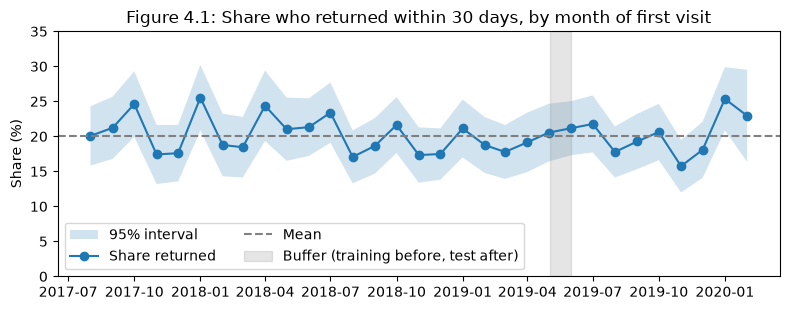

In [68]:
# Figure 4.1: Share who returned within 30 days by month of first visit (with 95% interval)
per_month_ret = cohort.groupby(cohort["day"].dt.to_period("M"))["returned"].agg(["mean", "size"])
se = np.sqrt(per_month_ret["mean"] * (1 - per_month_ret["mean"]) / per_month_ret["size"])
x = per_month_ret.index.to_timestamp()

plt.figure(figsize=(8, 3.2))
plt.fill_between(x, (per_month_ret["mean"] - 1.96 * se) * 100, (per_month_ret["mean"] + 1.96 * se) * 100, alpha=0.2,
                 label="95% interval")
plt.plot(x, per_month_ret["mean"] * 100, marker="o", label="Share returned")
plt.axhline(cohort["returned"].mean() * 100, color="grey", linestyle="--", label="Mean")
plt.axvspan(TRAIN_END, CUTOFF, color="grey", alpha=0.2, label="Buffer (training before, test after)")
plt.title("Figure 4.1: Share who returned within 30 days, by month of first visit")
plt.ylabel("Share (%)")
plt.ylim(0, 35)
plt.legend(loc="lower left", ncol=2)
plt.tight_layout()
plt.show()

In [69]:
# Table 4.2: Is the return rate stable over time?
years = (cohort["day"] - cohort["day"].min()).dt.days / 365.25                     # years since 1 Aug 2017
trend = smf.logit("returned ~ years", data=cohort.assign(years=years)).fit(disp=0)

months_test = stats.chi2_contingency(pd.crosstab(cohort["day"].dt.to_period("M"), cohort["returned"]))
calendar_test = stats.chi2_contingency(pd.crosstab(cohort["day"].dt.month, cohort["returned"]))
novdec = cohort["day"].dt.month.isin([11, 12])
nd_test = stats.chi2_contingency(pd.crosstab(novdec, cohort["returned"]))
tt = cohort[cohort["set"] != "buffer"]
tt_test = stats.chi2_contingency(pd.crosstab(tt["set"], tt["returned"]))

table_4_2 = pd.DataFrame({
    "Test": ["Trend over time (OR per year)", "Difference between months (χ²)", "Difference between calendar months (χ²)",
             "Nov–Dec vs. rest (share %)", "Training vs. test (share %)"],
    "Result": [f"OR = {np.exp(trend.params['years']):.2f}",
                 f"χ² = {months_test[0]:.1f}, df = {months_test[2]}",
                 f"χ² = {calendar_test[0]:.1f}, df = {calendar_test[2]}",
                 f"{cohort.loc[novdec, 'returned'].mean() * 100:.1f} vs. {cohort.loc[~novdec, 'returned'].mean() * 100:.1f}",
                 f"{tt.loc[tt['set'] == 'train', 'returned'].mean() * 100:.1f} vs. {tt.loc[tt['set'] == 'test', 'returned'].mean() * 100:.1f}"],
    "p-value": [trend.pvalues["years"], months_test[1], calendar_test[1], nd_test[1], tt_test[1]],
}).set_index("Test")
table_4_2.round(4)

,Result,p-value
Test,,
Trend over time (OR per year),OR = 0.97,0.3930
Difference between months (χ²),"χ² = 43.8, df = 30",0.0495
Difference between calendar months (χ²),"χ² = 32.5, df = 11",0.0006
Nov–Dec vs. rest (share %),17.3 vs. 20.8,0.0003
Training vs. test (share %),20.1 vs. 20.1,0.9783


## 5. Features from the first visit

All features use information from the first session only. The model can then be applied immediately after the visit, and no information leaks from the future. The features are constructed on the whole cohort, but every analysis used to choose features is done on the training data only.

- **`charge_h` and `idle_h`:** charging time and time the car stood without charging (total duration minus charging time). The difference says something about the purpose (charging or parking/"hoarding") and cannot be seen from the total duration alone. Everything is in hours.
- **`hour_bin`:** the start time in four bins: morning (05–09), midday (10–15), evening (16–20) and night (21–04). The raw hour is cyclical (23 and 0 are close in time but far apart as numbers) and too fine-grained (Figure 5.1).
- **`weekday`:** day of the week (0 = Monday), which captures the difference between weekdays and weekends.
- **`site`:** the station name reduced to the location itself ("PALO ALTO CA / BRYANT #1" → "BRYANT"). Chargers at the same place are pooled, so there are fewer and larger categories.
- **`area`:** the postal code grouped into local (Palo Alto, 94301–94306), rest of the Bay Area (940xx–951xx) and outside/unknown. It measures the user's attachment to the city and avoids hundreds of postal code categories. The 14 users without a postal code are placed in "outside/unknown" rather than dropped.
- **Energy and fee** are taken directly from the first session.

In [70]:
# Features from the first visit (charge_h, idle_h and site were created in section 1)
cohort["hour"] = cohort["Start Date"].dt.hour
cohort["hour_bin"] = np.select([cohort["hour"].between(5, 9), cohort["hour"].between(10, 15), cohort["hour"].between(16, 20)],
                               ["morning", "midday", "evening"], default="night")
cohort["weekday"] = cohort["Start Date"].dt.day_of_week       # 0 = Monday

# Local (Palo Alto), rest of the Bay Area, or outside/unknown (missing postal codes end up here)
z = cohort["Driver Postal Code"]
cohort["area"] = np.select([z.between(94301, 94306), (z // 100).between(940, 951)],
                           ["local", "bay_area"], default="outside_or_unknown")

# Training and test data (the buffer is left out)
train = cohort[cohort["set"] == "train"].copy()
test = cohort[cohort["set"] == "test"].copy()
print("Training:", len(train), "users, test:", len(test), "users")

Training: 7306 users, test: 3247 users


### 5.1 Categorical features (Figure 5.1)

**What we do:** For each categorical feature we show the share of new users who returned within 30 days, with a 95% interval (training data, 7,306 users). Panel (a) shows the start time hour by hour (hours 7–22, which have at least 30 users each) and the four bins we group into (separated by vertical lines). The dashed line is the mean. The numbers behind the figure are in the table below it.

**What the result shows:** All four features separate groups with high and low return rates:
- **Time of day:** The share is highest in the morning (34–37% at 7–9 am), falls during the day and is lowest at 6–8 pm (about 14–15%). 10 am (30%) lies between morning and midday, but moving it to morning hardly changes the AUC (+0.003, Table 6.7). Overall, 36.0% of those whose first session is in the morning (05–09) return, compared with 15.3% in the evening. 
- **Area:** Local users from Palo Alto make up 10% of new users. 37.8% of them return, compared with 18.2% from the rest of the Bay Area and 16.7% from outside/unknown.
- **Weekday:** The share falls through the week from 29.7% on Monday to 19.0% on Friday. Saturday is lowest at 14.8%, even though it is the day with the most new users.
- **Station:** The share ranges from 13.1% (Hamilton) to 34.9% (Ted Thompson). The stations with the highest shares are small (Rinconada Library: 206 users, Ted Thompson: 318), and the same applies to night (137 users). Here the uncertainty is ±5–7 percentage points.

**What we use it for:** All four categorical features are included in the model, and time of day is grouped into four bins.

**Limitation:** These relationships are raw, and features may overlap (local users may, for example, charge in the morning more often). We build the the logistic regression to handle this (Table 6.2).

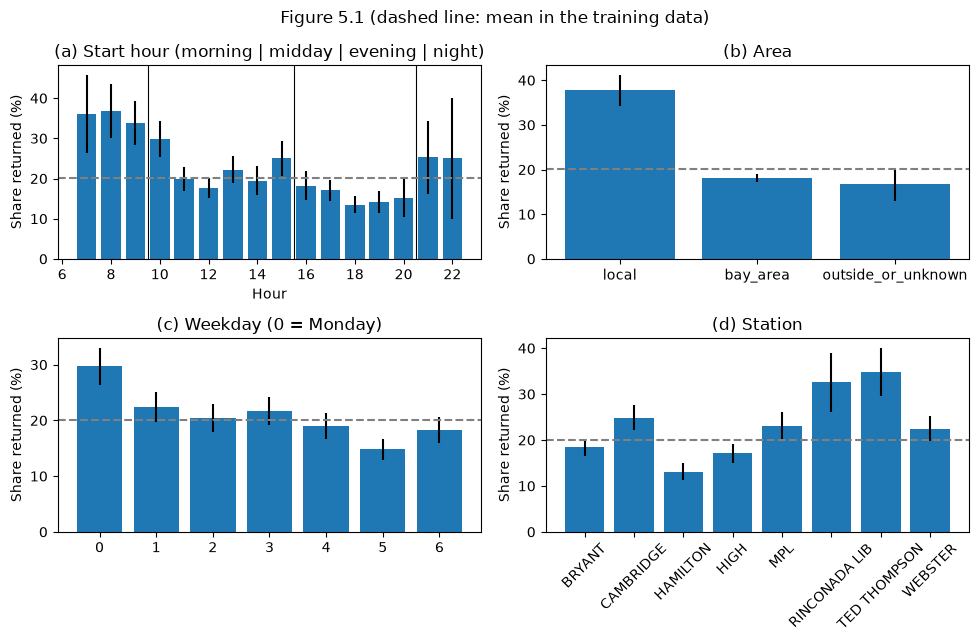

In [71]:
# Figure 5.1: Share who returned by categorical feature (training data, 95% interval)
mean_rate = train["returned"].mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))

# (a) Start hour by hour (hours 7–22 have at least 30 users each)
g = train.groupby("hour")["returned"].agg(["mean", "size"]).loc[7:22]
se = np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
axes[0, 0].bar(g.index, g["mean"] * 100, yerr=1.96 * se * 100)
for boundary in [9.5, 15.5, 20.5]:                                # boundaries between the four time bins
    axes[0, 0].axvline(boundary, color="black", linewidth=0.8)
axes[0, 0].axhline(mean_rate, color="grey", linestyle="--")
axes[0, 0].set_title("(a) Start hour (morning | midday | evening | night)")
axes[0, 0].set_xlabel("Hour")

# (b)–(d) Area, weekday and station
for ax, col, title, labels in [
    (axes[0, 1], "area", "(b) Area", ["local", "bay_area", "outside_or_unknown"]),
    (axes[1, 0], "weekday", "(c) Weekday (0 = Monday)", list(range(7))),
    (axes[1, 1], "site", "(d) Station", sorted(train["site"].unique())),
]:
    g = train.groupby(col)["returned"].agg(["mean", "size"]).loc[labels]
    se = np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
    ax.bar([str(l) for l in labels], g["mean"] * 100, yerr=1.96 * se * 100)
    ax.axhline(mean_rate, color="grey", linestyle="--")
    ax.set_title(title)
axes[1, 1].tick_params(axis="x", rotation=45)
for ax in axes.flat:
    ax.set_ylabel("Share returned (%)")

fig.suptitle("Figure 5.1 (dashed line: mean in the training data)")
plt.tight_layout()
plt.show()

In [72]:
# Numbers behind Figure 5.1: users and share who returned per category (training data)
rows = []
for f in ["hour_bin", "area", "weekday", "site"]:
    g = train.groupby(f)["returned"].agg(users="size", share_returned_pct="mean")
    g.index = [f"{f}: {c}" for c in g.index]
    rows.append(g)
shares = pd.concat(rows)
shares["share_returned_pct"] = (shares["share_returned_pct"] * 100).round(1)
shares

,users,share_returned_pct
hour_bin: evening,3078,15.3
hour_bin: midday,3486,21.3
hour_bin: morning,605,36.0
hour_bin: night,137,24.1
area: bay_area,6170,18.2
area: local,741,37.8
area: outside_or_unknown,395,16.7
weekday: 0,694,29.7
weekday: 1,907,22.4
weekday: 2,944,20.4


### 5.2 Numerical features: correlation and skewness (Tables 5.1–5.2)

**What we do:** We examine the four numerical features (energy, charging time, idle time and fee). Table 5.1 shows the Spearman correlation. We use Spearman rather than Pearson because the distributions are skewed and Spearman is robust to extreme values. Table 5.2 shows the mean, median, 95th and 99th percentiles, maximum and skewness before and after log(1 + x).

**What the result shows:** Energy, charging time and fee are strongly related (Spearman 0.84–0.92): the more energy delivered, the longer it takes and the more it costs. Idle time is almost uncorrelated with the others (0.01–0.14) and therefore carries separate information. All four features are right-skewed (skewness 2.2–18.1) with long tails. Idle time is the most extreme: the median is 0.01 hours, but the 99th percentile is 3.0 hours and the maximum 38.8 hours. log(1 + x) reduces the skewness markedly (e.g. energy from 2.7 to −0.4), but idle time remains skewed (3.2), because most users have almost no idle time.

**What we use it for:**
1. Energy, charging time and fee are so strongly correlated that they should not enter a logistic regression together, as correlated features make the coefficients unstable and hard to interpret. The fee is also almost determined by the energy, because the price per kWh is stable (Table 3.2). We keep energy and idle time.
2. Logistic regression does not require normally distributed features, but a linear term can be dominated by a few extreme values. We therefore use log(1 + x) for energy and idle time. We do not remove the extreme values, since they may reflect real behaviour such as hoarding. Tree-based models are unaffected by monotone transformations and can use the original values.

In [73]:
# Table 5.1: Spearman correlation between the numerical features (training data)
num_all = ["Energy (kWh)", "charge_h", "idle_h", "Fee"]
train[num_all].corr(method="spearman").round(2)

,Energy (kWh),charge_h,idle_h,Fee
Energy (kWh),1.00,0.88,0.01,0.92
charge_h,0.88,1.00,0.09,0.84
idle_h,0.01,0.09,1.00,0.14
Fee,0.92,0.84,0.14,1.00


In [74]:
# Table 5.2: Distribution and skewness of the numerical features (training data)
table_5_2 = train[num_all].describe(percentiles=[0.5, 0.95, 0.99]).T[["mean", "50%", "95%", "99%", "max"]]
table_5_2["skewness"] = train[num_all].skew()
table_5_2["skewness_after_log"] = np.log1p(train[num_all].clip(lower=0)).skew()
table_5_2.round(2)

,mean,50%,95%,99%,max,skewness,skewness_after_log
Energy (kWh),7.49,6.27,17.40,27.01,77.83,2.72,-0.43
charge_h,1.57,1.40,3.34,4.89,13.06,2.22,0.05
idle_h,0.23,0.01,1.33,2.97,38.78,18.14,3.21
Fee,1.90,1.52,4.41,7.70,79.94,12.41,0.43


### 5.3 Is the relationship linear in the log-odds? (Figure 5.2)

**What we do:** Logistic regression assumes that the log-odds of returning change linearly with each numerical feature. We divide the training users into groups by energy (deciles) and idle time, compute the share who returned in each group, and compare it with a logistic curve in log(1 + x). The x-axis uses the same log(1 + x) scale as the model.

**What the result shows:** For energy the share is flat (about 18–20%) up to about 11 kWh and then rises to about 25% for the largest sessions. The logistic curve captures the direction, but the increase is more concentrated at the top than the curve assumes. For idle time there is no clear relationship: the share is around 20% for most users, with a small dip at 1–4 hours.

**What we use it for:** A linear term is a reasonable approximation for energy. The alternatives (energy without log or in five groups) give practically the same cross-validated AUC (differences below 0.001, Table 6.7), so we keep the simple form. Idle time is included because it is a natural measure of hoarding, but it does not contribute significantly (Table 6.3).

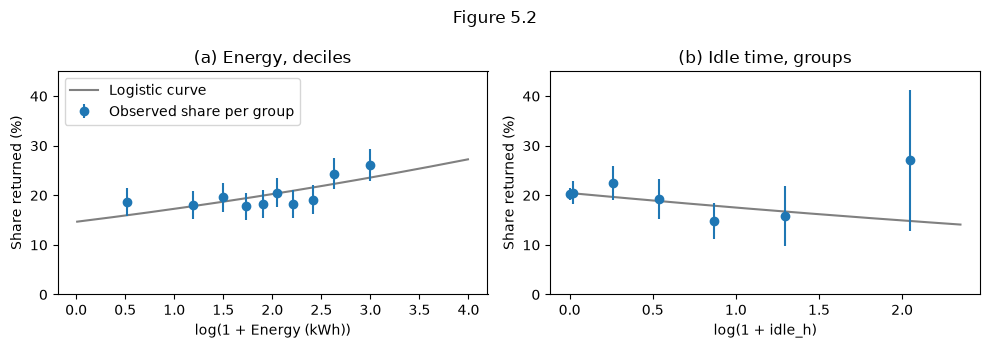

In [75]:
# Figure 5.2: Is the relationship linear in the log-odds? (training data)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
groups = {"Energy (kWh)": pd.qcut(train["Energy (kWh)"], 10),                                  # deciles
          "idle_h": pd.cut(train["idle_h"], [-0.001, 0.01, 0.1, 0.5, 1, 2, 4, np.inf])}

for ax, col in zip(axes, ["Energy (kWh)", "idle_h"]):
    df = pd.DataFrame({"x": np.log1p(train[col]), "returned": train["returned"]})
    g = df.groupby(groups[col], observed=True).agg(x=("x", "mean"), y=("returned", "mean"), n=("returned", "size"))
    se = np.sqrt(g["y"] * (1 - g["y"]) / g["n"])

    # logistic regression with only this feature, for comparison
    fit = smf.logit("returned ~ x", data=df).fit(disp=0)
    grid = pd.DataFrame({"x": np.linspace(df["x"].min(), df["x"].quantile(0.999), 200)})

    ax.plot(grid["x"], fit.predict(grid) * 100, color="grey", label="Logistic curve")
    ax.errorbar(g["x"], g["y"] * 100, yerr=1.96 * se * 100, fmt="o", label="Observed share per group")
    ax.set_xlabel(f"log(1 + {col})")
    ax.set_ylabel("Share returned (%)")
    ax.set_ylim(0, 45)
axes[0].set_title("(a) Energy, deciles")
axes[1].set_title("(b) Idle time, groups")
axes[0].legend(loc="upper left")
fig.suptitle("Figure 5.2")
plt.tight_layout()
plt.show()

### 5.4 Do users from outside California return less often? (Table 5.3)

**What we do:** We test the hypothesis that users with a postal code outside California are visitors and therefore return less often. We use training users with a known postal code and split them by whether the postal code is in California (first three digits 900–961). The difference is tested with a χ² test.

**What the result shows:** The hypothesis is not supported. 20.0% of Californian users return, compared with 23.9% of those from outside California. This points in the opposite direction of the hypothesis, but the difference is not statistically significant (p = 0.35). The group from outside California is only 117 users (1.6%), and the interval is wide.

**What we use it for:** We do not use state as a feature. What separates users is their attachment to the city (local or not), not the state (Figure 5.1).

In [76]:
# Table 5.3: Returns by state of postal code (training data with a known postal code)
known = train[train["Driver Postal Code"].notna()].copy()
known["state"] = np.where((known["Driver Postal Code"] // 100).between(900, 961), "California", "Outside California")

table_5_3 = known.groupby("state")["returned"].agg(users="size", share="mean")
se = np.sqrt(table_5_3["share"] * (1 - table_5_3["share"]) / table_5_3["users"])
table_5_3["share_pct"] = table_5_3["share"] * 100
table_5_3["ci_low_pct"] = (table_5_3["share"] - 1.96 * se) * 100
table_5_3["ci_high_pct"] = (table_5_3["share"] + 1.96 * se) * 100

print("χ² test, p =", round(stats.chi2_contingency(pd.crosstab(known["state"], known["returned"]))[1], 3))
table_5_3.drop(columns="share").round(1)

χ² test, p = 0.352


,users,share_pct,ci_low_pct,ci_high_pct
state,,,,
California,7183,20.0,19.1,20.9
Outside California,117,23.9,16.2,31.7


### 5.5 Table 5.4: Features in the logistic regression

The analyses above lead to the following choices:

| Feature | Type | Treatment in the model | Reference | Reason |
|---|---|---|---|---|
| Energy, `Energy (kWh)` | Numerical | log(1 + x), standardised | – | Right-skewed; log dampens extreme values (Table 5.2, Figure 5.2) |
| Idle time, `idle_h` (hours) | Numerical | log(1 + x), standardised | – | Measure of hoarding; almost uncorrelated with energy (Table 5.1) |
| Charging time, `charge_h` | Numerical | Left out | – | Spearman 0.88 with energy (Table 5.1) |
| Fee, `Fee` | Numerical | Left out | – | Spearman 0.92 with energy, and the price per kWh is stable (Table 3.2) |
| Time of day, `hour_bin` | Categorical (4) | Dummy variables | Evening (16–20) | Figure 5.1 |
| Weekday, `weekday` | Categorical (7) | Dummy variables | Monday | Figure 5.1 |
| Station, `site` | Categorical (8) | Dummy variables | Bryant | Figure 5.1; all 8 appear in both training and test (Table 4.1) |
| Area, `area` | Categorical (3) | Dummy variables | Rest of the Bay Area | Figure 5.1, Table 5.3 |
| Port type | Categorical | Left out | – | 10,908 of 10,912 first visits are Level 2 (Table 3.7) |

The model thus has 20 parameters plus an intercept. Standardisation makes the coefficients for energy and idle time comparable (per standard deviation). The reference category is the default in statsmodels: the first category in alphabetical or numerical order.

## 6. Logistic regression

Logistic regression is our first and most interpretable model. It models the log-odds of returning as a linear function of the features and therefore gives both a probability per user and odds ratios that show who returns.

**Positive class.** The model estimates p = P(returns within 30 days). Leavers are the group we want to target, and their score is 1 − p. This is the same model (the coefficients simply change sign), but "returns" is the rare class (20%), which makes the odds ratios and PR-AUC easier to interpret.

### 6.1 Estimation without regularisation (Table 6.1)

**What we do:** We fit the model in statsmodels by ordinary maximum likelihood, i.e. without regularisation. Energy and idle time enter as `z_energy` and `z_idle`: log(1 + x), standardised with the mean and standard deviation of the training data, so the test data are transformed in the same way without being used. `C(...)` in the formula turns a categorical feature into dummy variables. The same fitted model gives the odds ratios with confidence intervals and p-values (section 6.3) and the predicted probabilities (sections 6.4–6.5).

**What the result shows:** The training data contain 1,466 returning users (the rarer class) for 20 parameters, i.e. about 73 per parameter (Table 6.1).

**What we use it for:** Regularisation protects against overfitting when there are many parameters relative to the data. With about 73 returning users per parameter, we consider the risk to be small, so we do not regularise. The AUC on the training data, in cross-validation and on the test data confirms that the model does not overfit (Table 6.4).

In [77]:
# Model setup: log(1 + x) and standardisation of energy and idle time,
# using the mean and standard deviation of the training data for both training and test data
for col, name in [("Energy (kWh)", "z_energy"), ("idle_h", "z_idle")]:
    mean, sd = np.log1p(train[col]).mean(), np.log1p(train[col]).std()
    train[name] = (np.log1p(train[col]) - mean) / sd
    test[name] = (np.log1p(test[col]) - mean) / sd

# The features from Table 5.4. C(...) makes dummy variables; the reference is the first category.
TERMS = ["z_energy", "z_idle", "C(hour_bin)", "C(weekday)", "C(site)", "C(area)"]
FORMULA = "returned ~ " + " + ".join(TERMS)
print(FORMULA)

model = smf.logit(FORMULA, data=train).fit(disp=0)            # maximum likelihood, no regularisation
y_train, y_test = train["returned"], test["returned"]
p_train, p_test = model.predict(train), model.predict(test)   # P(returns) for each user

returned ~ z_energy + z_idle + C(hour_bin) + C(weekday) + C(site) + C(area)


In [78]:
# Table 6.1: Returning users per parameter (training data)
pd.DataFrame({
    "training_users": [len(train)],
    "returning_users": [y_train.sum()],
    "parameters": [int(model.df_model)],                      # excluding the intercept
    "returning_per_parameter": [y_train.sum() / model.df_model],
}).round(1)

,training_users,returning_users,parameters,returning_per_parameter
0,7306,1466,20,73.3


### 6.2 Time-based cross-validation

To evaluate the model on the training data alone (Table 6.4) and to compare alternative choices without using the test data (Table 6.7), we use time-based cross-validation with four folds (`TimeSeriesSplit`): the model is trained on the oldest users and validated on the next ones, just as in the final split. Between the training and validation parts we skip users corresponding to about 30 days, so that no training label depends on the validation period – the same idea as the buffer in section 4. We use four folds rather than five because with five the first training fold would end in October 2017 and contain no November–December users, so the November–December indicator in Table 6.7 could not be estimated.

In [79]:
# Time-based cross-validation on the training data (used in Tables 6.4 and 6.7)
CV_GAP = int(round(len(train) * WINDOW / (train["day"].max() - train["day"].min()).days))   # users in about 30 days
print("Gap:", CV_GAP, "users (about 30 days)")

def cv_auc(formula, data):
    """Mean and standard deviation of the AUC over four time-based folds."""
    aucs = []
    for a, b in TimeSeriesSplit(n_splits=4, gap=CV_GAP).split(data):
        fit = smf.logit(formula, data=data.iloc[a]).fit(disp=0)
        aucs.append(roc_auc_score(data["returned"].iloc[b], fit.predict(data.iloc[b])))
    return np.mean(aucs), np.std(aucs)

Gap: 344 users (about 30 days)


### 6.3 Who returns? (Tables 6.2–6.3, Figure 6.1)

**What we do:** Table 6.2 shows, for each dummy variable, the raw odds ratio (logistic regression with this feature only) and the adjusted odds ratio from the model with a 95% confidence interval and p-value. Odds ratios are relative to the reference category (evening, Monday, Bryant and rest of the Bay Area; Table 5.4). The number of users and the share who returned in each category are in the table under Figure 5.1. For energy and idle time they are per standard deviation of log(1 + x); for energy this corresponds to roughly doubling (1 + kWh). Figure 6.1 shows the adjusted odds ratios graphically, with the raw ones for comparison. Table 6.3 tests for each feature whether it improves the model (likelihood-ratio test with all of the feature's dummy variables at once).

**What the result shows:**
- **Area:** Local users from Palo Alto have 2.7 times the odds of returning compared with users from the rest of the Bay Area. Outside/unknown does not differ (0.89; p = 0.43).
- **Time of day:** A first visit in the morning has 2.7 times the odds of an evening visit, compared with 1.7 at night and 1.4 at midday. Night is based on only 137 users and therefore has a wide interval.
- **Weekday:** Monday has the highest odds. All other days are lower, especially Saturday (0.45) and Sunday (0.50).
- **Station:** Ted Thompson (1.9), Rinconada Library (1.6) and Cambridge (1.3) are above Bryant, Hamilton (0.70) below. High, MPL and Webster do not differ significantly.
- **Numerical features:** Energy has a weak positive relationship (1.15 per standard deviation, i.e. about 15% higher odds when energy roughly doubles). Idle time shows no clear relationship (0.95; p = 0.11).
- **Overall (Table 6.3):** Area, time of day, station, weekday and energy all contribute significantly (p < 0.001); idle time does not (p = 0.10). This is one test per feature instead of 20 separate tests, so the risk of chance findings is small.

**Raw vs. adjusted:** The effect of being local hardly changes when adjusting for the other features (raw 2.74, adjusted 2.72). It is therefore not because local users charge at particular times or places. The effects of morning (3.11 → 2.66) and Ted Thompson (2.38 → 1.94) become smaller, so they partly overlap with other features.

**What we use it for:** Returning is most likely for local users and weekday-morning first visits. The typical leaver is not local and charges in the evening or at the weekend. 

**Limitation:** The coefficients are associations, not causal effects. The model is linear in the features and has no interactions. Two obvious interactions (local × morning and local × weekend) were tested and do not improve the model (Table 6.7), but the tree models can capture more complex patterns.

In [80]:
# Table 6.2: Raw and adjusted odds ratios with 95% interval (training data)
# Raw OR: logistic regression with only this feature
raw_or = []
for t in TERMS:
    single = smf.logit(f"returned ~ {t}", data=train).fit(disp=0)
    raw_or.append(np.exp(single.params.drop("Intercept")))
raw_or = pd.concat(raw_or)

# Adjusted OR: the full model
ci = np.exp(model.conf_int())
table_6_2 = pd.DataFrame({
    "raw_OR": raw_or,
    "adjusted_OR": np.exp(model.params),
    "ci_low": ci[0],
    "ci_high": ci[1],
    "p": model.pvalues,
}, index=model.params.index.drop("Intercept"))
table_6_2.round(3)

,raw_OR,adjusted_OR,ci_low,ci_high,p
C(hour_bin)[T.midday],1.496,1.439,1.259,1.645,0.000
C(hour_bin)[T.morning],3.110,2.658,2.173,3.251,0.000
C(hour_bin)[T.night],1.752,1.723,1.135,2.614,0.011
C(weekday)[T.1],0.683,0.689,0.546,0.871,0.002
C(weekday)[T.2],0.609,0.644,0.509,0.814,0.000
C(weekday)[T.3],0.657,0.736,0.587,0.922,0.008
C(weekday)[T.4],0.555,0.598,0.476,0.750,0.000
C(weekday)[T.5],0.411,0.449,0.358,0.562,0.000
C(weekday)[T.6],0.531,0.503,0.398,0.637,0.000
C(site)[T.CAMBRIDGE],1.467,1.344,1.097,1.647,0.004


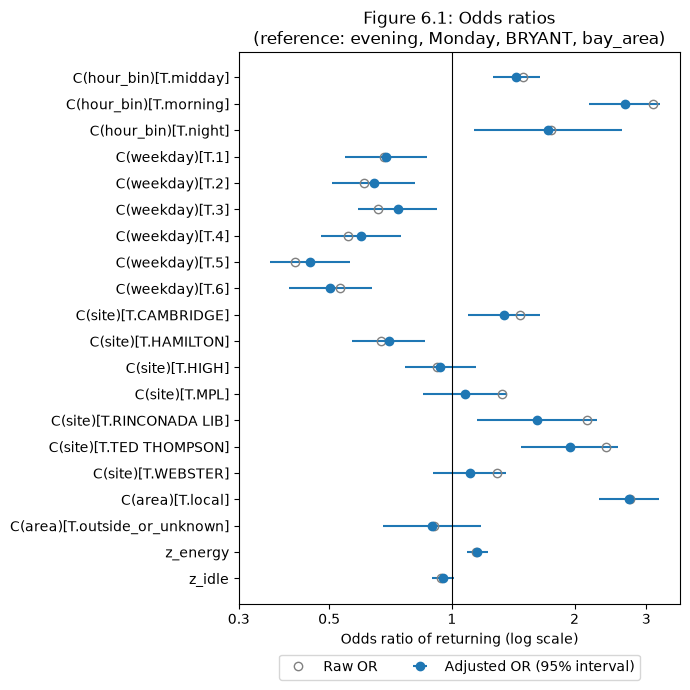

In [81]:
# Figure 6.1: Adjusted odds ratios with 95% interval (raw OR for comparison)
pos = np.arange(len(table_6_2))

plt.figure(figsize=(7, 7))
plt.errorbar(table_6_2["adjusted_OR"], pos,
             xerr=[table_6_2["adjusted_OR"] - table_6_2["ci_low"], table_6_2["ci_high"] - table_6_2["adjusted_OR"]],
             fmt="o", label="Adjusted OR (95% interval)")
plt.plot(table_6_2["raw_OR"], pos, "o", markerfacecolor="none", color="grey", label="Raw OR")
plt.axvline(1, color="black", linewidth=0.8)
plt.xscale("log")
plt.minorticks_off()                                          # avoids overlapping tick labels on the log axis
plt.xticks([0.3, 0.5, 1, 2, 3], ["0.3", "0.5", "1", "2", "3"])
plt.yticks(pos, table_6_2.index)
plt.gca().invert_yaxis()
plt.xlabel("Odds ratio of returning (log scale)")
plt.title("Figure 6.1: Odds ratios\n(reference: evening, Monday, BRYANT, bay_area)")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
plt.tight_layout()
plt.show()

In [82]:
# Table 6.3: Likelihood-ratio test per feature – the model with and without the feature (training data)
rows = []
for t in TERMS:
    reduced = smf.logit("returned ~ " + " + ".join(x for x in TERMS if x != t), data=train).fit(disp=0)
    lr = 2 * (model.llf - reduced.llf)
    df = model.df_model - reduced.df_model                   # the feature's number of parameters
    rows.append({"feature": t, "parameters": int(df), "chi2": lr, "p": stats.chi2.sf(lr, df)})
pd.DataFrame(rows).set_index("feature").sort_values("chi2", ascending=False).round(4)

,parameters,chi2,p
feature,,,
C(area),2,125.2749,0.0000
C(hour_bin),3,93.1916,0.0000
C(site),7,70.7311,0.0000
C(weekday),6,60.9076,0.0000
z_energy,1,21.9823,0.0000
z_idle,1,2.6789,0.1017


### 6.4 How well does the model work? (Tables 6.4–6.5, Figure 6.2)

**What we do:** The baseline gives all users the same probability (the share of returners in the training data) and is equivalent to random selection. We evaluate on the test data with ROC-AUC and PR-AUC, which assess how well the users are ranked, because the discount decision is a ranking. Because the business case also uses the predicted probabilities, we additionally report the Brier score (the mean squared difference between predicted probability and outcome) and the log loss, which measure how accurate the probabilities are; lower is better for both. We do not use accuracy: since 80% are leavers, a model that always predicts "does not return" gets 80% accuracy. To check for overfitting we compare with the AUC on the training data and in time-based cross-validation (section 6.2).

**What the result shows:**
- **Ranking:** The ROC-AUC is 0.662 vs. 0.500 for the baseline (Figure 6.2). A randomly chosen returning user thus gets a higher score than a randomly chosen leaver in about 66% of cases. The PR-AUC is 0.359 vs. 0.201, about 1.8 times the baseline. The model discriminates weakly to moderately, which is to be expected when it only knows the first visit.
- **Probability accuracy:** The Brier score is 0.150 vs. 0.161 for the baseline, and the log loss is 0.472 vs. 0.502, i.e. both are about 6–7% lower. The model's probabilities are thus more accurate than giving everyone the average rate, but the improvement is modest, in line with the moderate ranking ability.
- **No overfitting:** The AUC is 0.664 on the training data, 0.657 in cross-validation and 0.662 on the test data.
- **At the threshold 0.20** (the share of returners in the training data, chosen without the test data) the model flags 39% of the test users as "returns" and finds 58.3% of those who actually return (Table 6.5). Precision is 30.0% vs. 20.1% for random selection of the same number, and for leavers 86.3% vs. 79.9%. The course's default threshold of 0.5 would flag only 82 of 3,247 test users, because the model rarely gives probabilities above 0.5. Accuracy (64.3%) is below 80% because the threshold trades correct leaver predictions for finding more returners.


In [83]:
# Table 6.4: Ranking and probability accuracy – baseline and logistic regression
cv_mean, cv_sd = cv_auc(FORMULA, train)
p_baseline = np.full(len(y_test), y_train.mean())   # same probability for every test user

table_6_4 = pd.DataFrame({
    "auc_train": [0.5, roc_auc_score(y_train, p_train)],
    "auc_cv": [0.5, cv_mean],
    "auc_cv_sd": [np.nan, cv_sd],
    "auc_test": [0.5, roc_auc_score(y_test, p_test)],
    "pr_auc_test": [y_test.mean(), average_precision_score(y_test, p_test)],   # baseline = share who return
    "brier_test": [brier_score_loss(y_test, p_baseline), brier_score_loss(y_test, p_test)],
    "log_loss_test": [log_loss(y_test, p_baseline), log_loss(y_test, p_test)],
}, index=["Baseline (same probability for everyone)", "Logistic regression"])
table_6_4.round(3)

,auc_train,auc_cv,auc_cv_sd,auc_test,pr_auc_test,brier_test,log_loss_test
Baseline (same probability for everyone),0.500,0.500,NaN,0.500,0.201,0.161,0.502
Logistic regression,0.664,0.657,0.028,0.662,0.359,0.150,0.472


In [84]:
# Table 6.5: Classification on the test data at threshold 0.20 (share of returners in training)
t = y_train.mean()
pred = (p_test >= t).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
q, pi = pred.mean(), y_test.mean()     # share flagged, share who actually return

print(f"Threshold {t:.3f}: TP = {tp}, FP = {fp}, FN = {fn}, TN = {tn}")
print("Users with p > 0.5:", (p_test > 0.5).sum(), "of", len(p_test))
table_6_5 = pd.DataFrame({
    "logistic_regression_pct": [q, tp / (tp + fp), tp / (tp + fn), tn / (tn + fn), tn / (tn + fp), (tp + tn) / len(pred)],
    "random_same_number_pct": [q, pi, q, 1 - pi, 1 - q, q * pi + (1 - q) * (1 - pi)],
}, index=['Flagged as "returns"', "Precision, returns", "Recall, returns",
          "Precision, leaver", "Recall, leaver", "Accuracy"])
(table_6_5 * 100).round(1)

Threshold 0.201: TP = 381, FP = 887, FN = 272, TN = 1707
Users with p > 0.5: 82 of 3247


,logistic_regression_pct,random_same_number_pct
"Flagged as ""returns""",39.1,39.1
"Precision, returns",30.0,20.1
"Recall, returns",58.3,39.1
"Precision, leaver",86.3,79.9
"Recall, leaver",65.8,60.9
Accuracy,64.3,56.5


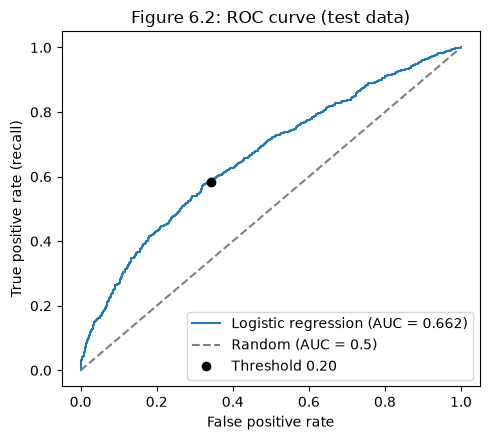

In [85]:
# Figure 6.2: ROC curve on the test data
fpr, tpr, _ = roc_curve(y_test, p_test)

plt.figure(figsize=(5, 4.5))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {roc_auc_score(y_test, p_test):.3f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random (AUC = 0.5)")
plt.plot(fp / (fp + tn), tp / (tp + fn), "o", color="black", label="Threshold 0.20")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("Figure 6.2: ROC curve (test data)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 6.5 Targeting the top X% (Table 6.6, Figure 6.3)

**What we do:** We rank the test users by the model's probability of leaving (1 − p), so that the least likely returners come first. For the top 10, 20, 30 and 50% we compute the share of leavers in the group (precision), the lift relative to random selection (79.9% leavers), the share of all leavers the group reaches (recall), and the share of discounts that go to users who returned anyway (waste).

**What the result shows:** In the top 10%, 90.1% are leavers vs. 79.9% for random selection, a lift of 1.13. The lift falls slightly with group size, to 1.09 at 50%. This sounds small, but the highest possible lift is 1.25, because 80% are already leavers. The more telling measure is waste: it falls from 20.1% for random selection to 9.9% in the top 10% and 13.0% in the top 50%. At the top, the model thus halves the waste. The top 10% reaches 11.3% of all leavers, the top 50% reaches 54.4% (Figure 6.3b).

**What we use it for:** Almost all new users are leavers, so the value of the model lies in avoiding discounts to users who would have returned anyway. The choice of X depends on the budget and the break-even calculation.

**Limitation:** The top consists of the users who are most certain to leave. According to Table 6.2 these are typically non-local weekend and evening users, who may be the least responsive to a discount. The model ranks by risk, not by how much a discount changes behaviour. The latter requires an experiment.

In [86]:
# Table 6.6: Targeting the X% with the lowest probability of returning (test data)
ranked = pd.DataFrame({"leaver": 1 - y_test, "p": p_test}).sort_values("p", kind="stable")   # lowest P(returns) first

rows = []
for k in [0.10, 0.20, 0.30, 0.50]:
    top = ranked.iloc[: int(k * len(ranked))]
    rows.append({"targeted_pct": k * 100, "users": len(top),
                 "precision_pct": top["leaver"].mean() * 100,
                 "lift": top["leaver"].mean() / ranked["leaver"].mean(),
                 "recall_pct": top["leaver"].sum() / ranked["leaver"].sum() * 100,
                 "waste_pct": (1 - top["leaver"].mean()) * 100})

print("Random selection: precision", round((1 - y_test.mean()) * 100, 1), "%, waste", round(y_test.mean() * 100, 1), "%")
pd.DataFrame(rows).round(2)

Random selection: precision 79.9 %, waste 20.1 %


,targeted_pct,users,precision_pct,lift,recall_pct,waste_pct
0,10.0,324,90.12,1.13,11.26,9.88
1,20.0,649,89.21,1.12,22.32,10.79
2,30.0,974,88.09,1.10,33.08,11.91
3,50.0,1623,87.00,1.09,54.43,13.00


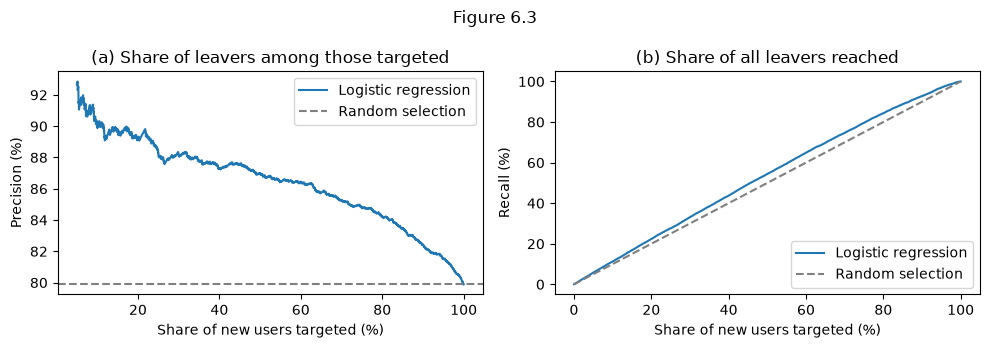

In [87]:
# Figure 6.3: Precision and recall for leavers by share targeted (test data)
leaver_sorted = ranked["leaver"].to_numpy()            # ranked as in Table 6.6: lowest P(returns) first
k = np.arange(1, len(leaver_sorted) + 1)
share = k / len(k) * 100
precision = np.cumsum(leaver_sorted) / k * 100
recall = np.cumsum(leaver_sorted) / leaver_sorted.sum() * 100
start = int(0.05 * len(k))                             # the first few users are very noisy

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(share[start:], precision[start:], label="Logistic regression")
ax1.axhline(leaver_sorted.mean() * 100, color="grey", linestyle="--", label="Random selection")
ax1.set_ylabel("Precision (%)")
ax1.set_title("(a) Share of leavers among those targeted")

ax2.plot(share, recall, label="Logistic regression")
ax2.plot([0, 100], [0, 100], color="grey", linestyle="--", label="Random selection")
ax2.set_ylabel("Recall (%)")
ax2.set_title("(b) Share of all leavers reached")

ax1.legend(loc="upper right")
ax2.legend(loc="lower right")
for ax in (ax1, ax2):
    ax.set_xlabel("Share of new users targeted (%)")
fig.suptitle("Figure 6.3")
plt.tight_layout()
plt.show()